In [9]:
import numpy as np

train = np.load("nn-2026-fii-homework-3/train.npz")
test = np.load("nn-2026-fii-homework-3/test.npz")

print(train["data"][0])
print(test)


[ 70   0   0   0   0  39   0 240   0   2   0 253 238 183   0   0   0  39
 172   0   0   0  93 170   0   0   0   0   0   0   0   0 253   0  80   0
   0   0   0   0 187   0   0   0   0   0   0   0  30   3   0   0   0   0
   0   0  81   0   0   0   0  80   0   0   0 249   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 250
   0   0   0 253 195 253   0   0  16   0   0 171   0 253   0 253   0   0
 148   0   0   0   0   0   0   0   0   0   0   0   0  24   0   0   0 154
 182   0   0 139   0   0   0   0   0   0   0   0   0 135   0   0   0   0
   0   0   0   0   0   0   0   0   0  56   0   0   0   0   0   0  16   0
 253   0   0   0 219   0   0  18   0   0   0 150   0  27   0   0   0   0
   0 119 253   0   0   0   0   0   0   0 198 253   0   0   0   0 241   0
   0   0   0   0   0   0   0 253 219   0   0  23   0   0   0  18   0   0
   0   0 253   0   0   0   0   0   0   0   0 253   0 229   0   0   0   0
  26   0   0 108   0   0   0   0 221   0 201   0   

Text(0.5, 1.0, 'Label: 9')

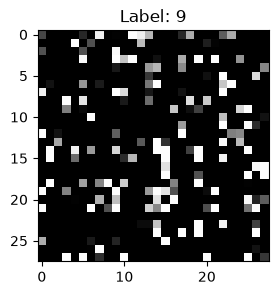

In [15]:
import matplotlib.pyplot as plt

image = train["data"][0].reshape(28, 28)

plt.figure(figsize=(3, 3))
plt.imshow(image, cmap="gray")

plt.title(f"Label: {train["labels"][0]}")

# plt.show() 

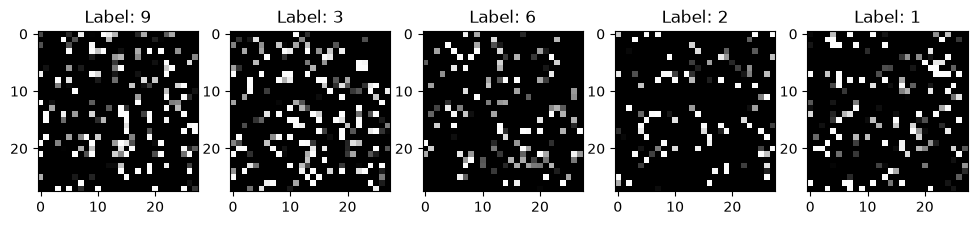

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i in range(5):
    img = train["data"][i].reshape(28, 28)
    axes[i].imshow(img, cmap="gray")

    axes[i].set_title(f"Label: {train["labels"][i]}")

### Forward Pass

In [ ]:
def relu(z):
    return np.maximum(0, z)

def softmax(z):
    z = z - np.max(z, axis=-1, keepdims=True)
    exp = np.exp(z)
    expsum = np.sum(exp, axis=-1, keepdims=True)
    return exp / expsum

def forward(X, params):
    """
    Parameters:
        X - inputs (m, 784)
        params - dict with keys 'W1', 'b1', 'W2', 'b2'

    Returns:
        y_hat - predicted probability distribution (m, 10)
        cache: dict containing all intermediate values needed by backprop
    """

    # Layer 1 (hidden)
    z1 = X @ params['W1'] + params['b1'] # (m, 784) @ (784, 100) + (100,) = (m, 100)
    a1 = relu(z1) # (m, 100)

    # Layer 2
    z2 = a1 @ params['W2'] + params['b2'] # (m, 100) @ (100, 10) + (10, ) = (m, 10)
    y_hat = softmax(z2) # (m, 10)

    cache = {'X': X, 'z1': z1, 'a1': a1, 'z2': z2, 'y_hat': y_hat}

    return y_hat, cache

### Backpropagation

In [ ]:
def backward(y_true, cache, params):
    """
    Parameters:
        y_true: one-hot ground truth labels (m, 10)
        cache:  dict containing ('X', 'z1', 'a1', 'z2', 'y_hat')
        params: dict containing ('W1', 'b1', 'W2', 'b2')

    Returns:
        grads: dict containing ('dW2', 'db2', 'dW1', 'db1')
    """
    m = y_true.shape[0]
    dout2 = cache['y_hat'] - y_true # (m, 10) - (m, 10)
    dout1 = dout2 @ params['W2'].T * (cache['z1'] > 0) # (m, 10) @ (10, 100) * (m, 100)

    dW2 = 1/m * cache['a1'].T @ dout2 # (100, m) @ (m, 10)
    db2 = 1/m * np.sum(dout2, axis=0)

    dW1 = 1/m * cache['X'].T @ dout1 # (m, 784) @ ()
    db1 = 1/m * np.sum(dout1, axis=0)

    grads = {'dW2': dW2, 'db2': db2, 'dW1': dW1, 'db1': db1}
    return grads